# Modelo Final

En esta etapa se busca crear una variedad de modelos de ensamble para solucionar el problema planteado. Para ello, deberán tomar en cuenta las siguientes consideraciones:  
* Incluir la optimización de hiperparámetros para los modelos más relevantes.  
* Utilizar algoritmos que apliquen tanto estrategias de ensamble homogéneas como heterogéneas.  
* Para las estrategias de stacking y/o blending, se deberán emplear los modelos individuales de mejor rendimiento obtenidos en la fase anterior.  

Una vez que se han generado los modelos de ensamble, sintetizar los resultados en una tabla comparativa en la que se incluyan los modelos individuales de la fase previa.   
* Los modelos deben ser ordenados por la métrica principal, pero el resumen debe incorporar otras métricas pertinentes.  
* Se deberán incluir también los tiempos de entrenamiento.  
* Se elige el modelo final alineado con los objetivos y necesidades del negocio.  

La solución propuesta requiere de que se etiqueten de manera manual una serie de imágenes de muestra anónimas y se generen datos para que la solución pueda re-entrenarse o reconfigurarse para mejorar su desempeño.  
Para realizar tales acciones con facilidad se refactorizaron los siguientes códigos:
1. **Adquisición**.  Consiste en obtener fotografías con un recuadro sobre la cara para anonimizar y evitar problemas con el manejo de PII.
2. **Limpieza**.  (opcional/recomendado) Consiste en borrar manualmente imagenes de mala calidad para el entrenamiento de la carpeta ../DataCapture/Raw/xxx.jpg
3. **Etiquetado**.  Código que escanea las detecciones actuales sobre el dataset, si la imagen es nueva se espera que se le dibujen nuevos rectángulos para mejorar las detecciones.  Esto genera un archivo *"../DataCapture/anotaciones.csv"*
4. **Ingenieria de características**.  Se genera dataset *"..DataCapture/revisado.csv"*.  Es un script encadenado al de etiquetado
5. **Entrenamiento**.  Se ejecuta entrenamiento con FasterCNN.  El modelo de salida se guarda en *"../Models/xxx.pth"*
6. **Ejecución**.  Se realiza streaming con la capacidad de identificar en pruebas reales detecciones  

Si se quiere que la solución se replique aprovechando el dataset de imagenes ya en depurado en el repositorio **basta con realizar solo los pasis 5 y 6**.  Esto debido a que los modelos *.pth son pesados o dificiles de almacenar en un repositorio de github por lo que debe de reproducirse en el equipo a utilizar al final.

Dicha refactorización permite un producto mínimo viable para ejecutar.  La refactorización para una ejecución en limpio de la solución consta de ejecutar los siguientes scripts:  
* ../DataCapture/foto_anon.py
* ../DataCapture/Etiquetado.py
* ../Scripts/train.py
* ../Scripts/train.py

Los scirpts condensan la secuencia de pasos explicada al inicio.  Los modelos de IA para la solución propuesta pueden variar y se evaluará su desempeño en forma general, sin embargo la etapa de adquisición sigue siendo común para cualquier modelo a ejecutar ya que **a partir de dicha adquisición y etiquetado es que surgen los modelos y su desempeño**

## Scripts para datos de entrenamiento (generación y supervisión)  
A continuación se detallan los scripts previamente refactorizados pero adaptados para correr en la libreta actual de Jupyter.  

### Adquisición  
El script inicia un streaming y guarda las fotos  en *"../DataCapture/raw/xxx.jpg"*.  En caso de no buscar añadir imágenes extras hacer caso omiso.  
Para efectos de Markdown se mostrarán imagenes capturadas recientemente.  Sacado del código refactorizado en *"../DataCapture/foto_anon.py"*:

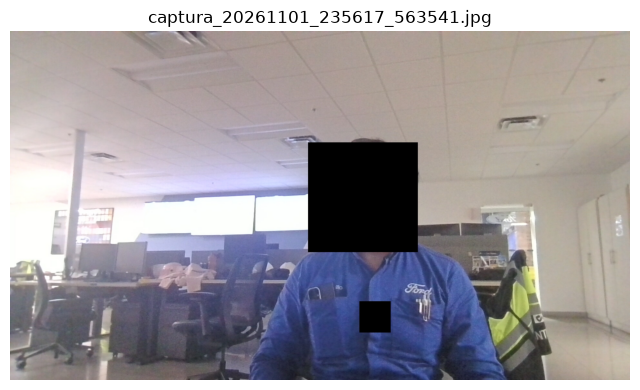

In [7]:
import cv2
import time
from pathlib import Path
from datetime import datetime
import matplotlib.pyplot as plt

# Configuración
CAMERA_INDEX = 0
COOLDOWN_SECONDS = 5.0
OUTPUT_DIR = Path("../DataCapture/raw").resolve()

# Por precaución, no guardar una captura si el detector no encuentra
# ningún rostro. Esto no garantiza que haya detectado todos los rostros.
SAVE_ONLY_IF_FACE_DETECTED = True

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
if face_cascade.empty():
    raise RuntimeError("No se pudo cargar el detector de rostros de OpenCV.")

cap = cv2.VideoCapture(CAMERA_INDEX)
# Configurar resolución deseada
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1920)  # Ancho
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 1080) # Alto

if not cap.isOpened():
    raise RuntimeError("No se pudo abrir la webcam.")

last_attempt = time.monotonic() - COOLDOWN_SECONDS
status = "Esperando captura..."

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            print("No se pudo leer un fotograma de la webcam.")
            break

        height, width = frame.shape[:2]

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        # Crear la imagen anonimizada; no se guarda el fotograma original.
        anonymized = frame.copy()

        for (x, y, w, h) in faces:
            # Ampliar la máscara alrededor del rostro detectado.
            margin_x = int(0.25 * w)
            margin_y = int(0.25 * h)

            x1 = max(0, x - margin_x)
            y1 = max(0, y - margin_y)
            x2 = min(width, x + w + margin_x)
            y2 = min(height, y + h + margin_y)

            # Rectángulo negro opaco.
            cv2.rectangle(
                anonymized,
                (x1, y1),
                (x2, y2),
                (0, 0, 0),
                thickness=-1
            )

        now = time.monotonic()

        # Intentar guardar una nueva captura al cumplirse el intervalo.
        if now - last_attempt >= COOLDOWN_SECONDS:
            last_attempt = now

            if len(faces) > 0 or not SAVE_ONLY_IF_FACE_DETECTED:
                filename = datetime.now().strftime(
                    "captura_%Y%m%d_%H%M%S_%f.jpg"
                )
                output_path = OUTPUT_DIR / filename

                saved = cv2.imwrite(
                    str(output_path),
                    anonymized,
                    [cv2.IMWRITE_JPEG_QUALITY, 95]
                )
                status = (
                    f"Guardada: {filename}"
                    if saved
                    else "Error al guardar la captura"
                )
            else:
                status = "No guardada: no se detectó ningún rostro"

        # Mostrar una copia con el estado; el texto no se añade al archivo.
        preview = anonymized.copy()
        cv2.putText(
            preview,
            status,
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )
        cv2.imshow("Vista anonimizada — pulsa q para salir", preview)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
    # Mostrar las imagenes capturadas recientemente:
    extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    archivos = [
        p for p in OUTPUT_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in extensiones
    ]

    if archivos:
        ultimo = max(archivos, key=lambda p: p.stat().st_mtime)
        imagen = cv2.imread(str(ultimo))

        if imagen is not None:
            plt.figure(figsize=(8, 6))
            plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            plt.title(ultimo.name)
            plt.axis("off")
            plt.show()
            plt.close()
        else:
            print(f"No se pudo leer la imagen: {ultimo.name}")
    else:
        print("No se encontraron imágenes en OUTPUT_DIR.")

### Etiquetado  
El etiquetado cuenta con menú para desplazar imagenes dando clic en "N" para revisar la siguiente y "P" para previa.  Dicho menú se hizo con ayuda de (GPT-6 Luna) y se combinó en ese espacio de trabajo el manejo del dataset con las coordenadas de los objetos a detectar como **"No cumple"**.  
El script se sacó de la refactorización guardada en el script *"../DataCapture/Etiquetado.py"*:

Registros guardados en el CSV: 88
Archivo revisado guardado: C:\Users\mlope243\Documents\VSCode\TC5031.10_ProyectoIntegrador\DataCapture\revisado.csv (52 imágenes)


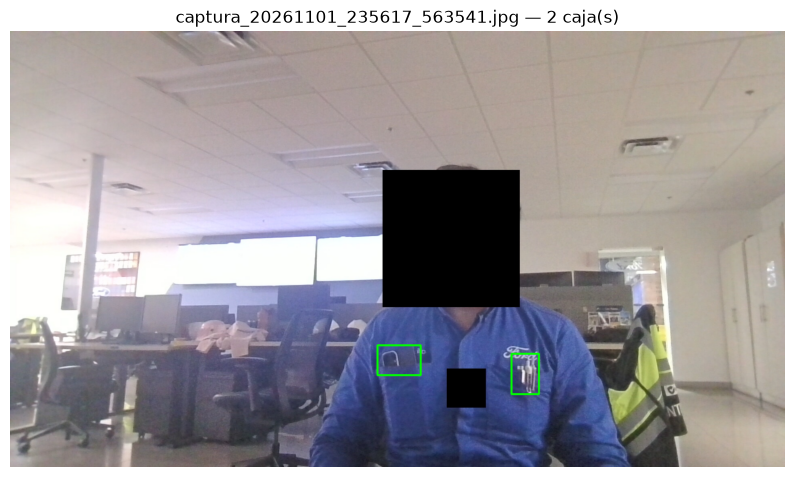

In [13]:
import csv
import os
from pathlib import Path
import matplotlib.pyplot as plt

import cv2

#actual_dir = Path(__file__).resolve().parent
actual_dir = Path("..").resolve()
#actual_dir = actual_dir.parent / "DataCapture"
IMAGE_DIR = actual_dir / "DataCapture/raw/"
CSV_OUT = actual_dir / "DataCapture/anotaciones.csv"
Revisado_OUT = actual_dir / "DataCapture/revisado.csv"

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
WINDOW_NAME = "Anotador de objetos"

# True: empieza en la primera imagen que aún no aparece en el CSV.
# False: comienza desde la primera imagen para permitir revisar todo.
RESUME_AT_FIRST_UNREVIEWED = True


class Annotator:
    def __init__(self, image_paths, csv_path, resume=True):
        self.image_paths = image_paths
        self.csv_path = csv_path
        self.columns = [
            "imagen", "x", "y", "w", "h", "ImageWidth", "ImageHeight"
        ]

        self.index = 0
        self.image = None
        self.image_name = None
        self.current_boxes = []
        self.first_point = None

        # Filas ya existentes y nombres de imágenes con algún registro.
        self.rows = []
        self.recorded_images = set()

        # Cajas recuperadas del CSV, por nombre de imagen.
        self.boxes_by_image = {}

        self.csv_path.parent.mkdir(parents=True, exist_ok=True)
        self.load_csv()

        # Reanudar en la primera imagen sin registro.
        if resume:
            self.index = next(
                (
                    i for i, path in enumerate(self.image_paths)
                    if path.name not in self.recorded_images
                ),
                0,  # Si todas están registradas, permite recorrer desde el inicio.
            )

        self.load_current_image()

    def load_csv(self):
        """Carga los registros y reconstruye las cajas existentes."""
        if not self.csv_path.exists() or self.csv_path.stat().st_size == 0:
            self.rows = []
            return

        with self.csv_path.open(
            "r", newline="", encoding="utf-8-sig"
        ) as f:
            reader = csv.DictReader(f)

            if reader.fieldnames != self.columns:
                raise ValueError(
                    "Las columnas del CSV no coinciden con las esperadas.\n"
                    f"Esperadas: {self.columns}\n"
                    f"Encontradas: {reader.fieldnames}"
                )

            for raw_row in reader:
                row = {
                    col: (raw_row.get(col) or "").strip()
                    for col in self.columns
                }

                image_name = row["imagen"]
                if not image_name:
                    continue

                self.rows.append(row)
                self.recorded_images.add(image_name)

                # Una fila con x, y, w, h numéricos representa una caja.
                try:
                    x = int(float(row["x"]))
                    y = int(float(row["y"]))
                    w = int(float(row["w"]))
                    h = int(float(row["h"]))
                except (ValueError, TypeError):
                    # Por ejemplo: fila vacía que marca imagen sin detecciones.
                    continue

                if w <= 0 or h <= 0:
                    continue

                # El anotador original guardó w/h incluyendo el píxel final.
                x2 = x + w - 1
                y2 = y + h - 1

                self.boxes_by_image.setdefault(image_name, []).append(
                    (x, y, x2, y2)
                )

    def save_csv(self):
        """Reescribe el CSV con los registros actuales."""
        temp_path = self.csv_path.with_suffix(self.csv_path.suffix + ".tmp")

        with temp_path.open("w", newline="", encoding="utf-8-sig") as f:
            writer = csv.DictWriter(f, fieldnames=self.columns)
            writer.writeheader()
            writer.writerows(self.rows)

        # Reemplazo para evitar dejar un CSV a medio escribir.
        os.replace(temp_path, self.csv_path)

    def load_current_image(self):
        """Carga la imagen indicada por el índice y sus cajas previas."""
        self.image = None
        self.image_name = None
        self.current_boxes = []
        self.first_point = None

        while self.index < len(self.image_paths):
            path = self.image_paths[self.index]
            image = cv2.imread(str(path))

            if image is not None:
                self.image = image
                self.image_name = path.name
                self.current_boxes = list(
                    self.boxes_by_image.get(self.image_name, [])
                )
                return

            print(f"No se pudo leer; se omitirá: {path.name}")
            self.index += 1

    def on_mouse(self, event, x, y, flags, param):
        """Dos clics izquierdos definen las esquinas de una caja."""
        if event != cv2.EVENT_LBUTTONDOWN or self.image is None:
            return

        height, width = self.image.shape[:2]
        x = max(0, min(int(x), width - 1))
        y = max(0, min(int(y), height - 1))

        if self.first_point is None:
            self.first_point = (x, y)
            return

        x0, y0 = self.first_point
        x1, y1 = min(x0, x), min(y0, y)
        x2, y2 = max(x0, x), max(y0, y)

        if x2 > x1 and y2 > y1:
            box_width = x2 - x1 + 1
            box_height = y2 - y1 + 1

            # Si la imagen tenía una fila vacía de "sin detecciones",
            # se elimina: ahora sí tiene una detección.
            self.rows = [
                row for row in self.rows
                if not (
                    row["imagen"] == self.image_name
                    and not row["x"] and not row["y"]
                    and not row["w"] and not row["h"]
                )
            ]

            self.current_boxes.append((x1, y1, x2, y2))

            row = {
                "imagen": self.image_name,
                "x": x1,
                "y": y1,
                "w": box_width,
                "h": box_height,
                "ImageWidth": width,
                "ImageHeight": height,
            }
            self.rows.append({col: str(row[col]) for col in self.columns})
            self.recorded_images.add(self.image_name)
            self.boxes_by_image[self.image_name] = list(self.current_boxes)

            # Guardado inmediato de cada caja completa.
            self.save_csv()

        self.first_point = None

    def render(self):
        """Dibuja las cajas existentes y nuevas sobre la imagen."""
        display = self.image.copy()

        for x1, y1, x2, y2 in self.current_boxes:
            cv2.rectangle(display, (x1, y1), (x2, y2), (0, 255, 0), 2)

        if self.first_point is not None:
            cv2.drawMarker(
                display,
                self.first_point,
                (0, 0, 255),
                markerType=cv2.MARKER_CROSS,
                markerSize=14,
                thickness=2,
            )

        height = display.shape[0]

        cv2.putText(
            display,
            f"Imagen {self.index + 1}/{len(self.image_paths)}: "
            f"{self.image_name} | Cajas: {len(self.current_boxes)}",
            (10, 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.60,
            (0, 255, 255),
            2,
        )

        cv2.putText(
            display,
            "Dos clics: caja | N: siguiente | P: anterior | Q: salir",
            (10, height - 15),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 255),
            2,
        )

        return display

    def next_image(self):
        """Avanza y registra una fila vacía solo si nunca se registró."""
        if self.image is None:
            return

        # Solo registra una fila vacía si no hay cajas y no existe ya
        # ningún registro para esta imagen.
        if (
            not self.current_boxes
            and self.image_name not in self.recorded_images
        ):
            height, width = self.image.shape[:2]
            row = {
                "imagen": self.image_name,
                "x": "",
                "y": "",
                "w": "",
                "h": "",
                "ImageWidth": width,
                "ImageHeight": height,
            }
            self.rows.append(row)
            self.recorded_images.add(self.image_name)
            self.save_csv()

        self.index += 1
        self.load_current_image()

    def previous_image(self):
        """Retrocede sin crear registros ni modificar las anotaciones."""
        if self.index > 0:
            self.index -= 1
            self.load_current_image()
    
def generar_revisado(csv_anotaciones, csv_revisado):
    """Crea revisado.csv con una fila por imagen y su etiqueta de objeto."""
    orden_imagenes = []
    imagenes_vistas = set()
    imagenes_con_objeto = set()

    with csv_anotaciones.open(
        "r", newline="", encoding="utf-8-sig"
    ) as archivo:
        reader = csv.DictReader(archivo)

        columnas_requeridas = {"imagen", "x", "y", "w", "h"}
        faltantes = columnas_requeridas - set(reader.fieldnames or [])
        if faltantes:
            raise ValueError(
                f"Faltan columnas en {csv_anotaciones.name}: {sorted(faltantes)}"
            )

        for numero_fila, row in enumerate(reader, start=2):
            nombre = (row.get("imagen") or "").strip()
            if not nombre:
                continue

            if nombre not in imagenes_vistas:
                imagenes_vistas.add(nombre)
                orden_imagenes.append(nombre)

            valores = [
                (row.get(columna) or "").strip()
                for columna in ("x", "y", "w", "h")
            ]

            # Los cuatro campos vacíos representan una imagen sin objeto.
            if all(valor == "" for valor in valores):
                continue

            # Una caja debe tener sus cuatro valores.
            if any(valor == "" for valor in valores):
                raise ValueError(
                    f"Caja incompleta en fila {numero_fila}, imagen {nombre}"
                )

            try:
                x, y, ancho, alto = map(float, valores)
            except ValueError as error:
                raise ValueError(
                    f"Coordenadas no numéricas en fila {numero_fila}, "
                    f"imagen {nombre}"
                ) from error

            if ancho <= 0 or alto <= 0:
                raise ValueError(
                    f"Caja con ancho o alto no positivo en fila {numero_fila}, "
                    f"imagen {nombre}"
                )

            imagenes_con_objeto.add(nombre)

    csv_revisado.parent.mkdir(parents=True, exist_ok=True)

    with csv_revisado.open(
        "w", newline="", encoding="utf-8-sig"
    ) as archivo:
        writer = csv.writer(archivo)
        writer.writerow(["imagen", "tiene_objeto"])
        writer.writerows(
            (nombre, int(nombre in imagenes_con_objeto))
            for nombre in orden_imagenes
        )

    return len(orden_imagenes)

## Función exclusiva para el markdown
def mostrar_ultima_imagen_con_cajas(image_dir, csv_anotaciones):
    """Muestra la imagen más recientemente modificada con sus cajas anotadas."""
    archivos = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    ]

    if not archivos:
        print("No se encontraron imágenes en la carpeta.")
        return

    # Selecciona por fecha de modificación del archivo.
    ultima = max(archivos, key=lambda p: p.stat().st_mtime)
    imagen = cv2.imread(str(ultima))

    if imagen is None:
        print(f"No se pudo leer la imagen: {ultima.name}")
        return

    cajas = []

    if csv_anotaciones.exists():
        with csv_anotaciones.open(
            "r", newline="", encoding="utf-8-sig"
        ) as archivo:
            reader = csv.DictReader(archivo)

            for row in reader:
                if (row.get("imagen") or "").strip() != ultima.name:
                    continue

                try:
                    x = int(float(row["x"]))
                    y = int(float(row["y"]))
                    w = int(float(row["w"]))
                    h = int(float(row["h"]))
                except (ValueError, TypeError, KeyError):
                    # Omite filas vacías que representan imágenes sin objeto.
                    continue

                if w > 0 and h > 0:
                    cajas.append((x, y, x + w - 1, y + h - 1))

    alto, ancho = imagen.shape[:2]

    for x1, y1, x2, y2 in cajas:
        x1 = max(0, min(x1, ancho - 1))
        x2 = max(0, min(x2, ancho - 1))
        y1 = max(0, min(y1, alto - 1))
        y2 = max(0, min(y2, alto - 1))

        cv2.rectangle(imagen, (x1, y1), (x2, y2), (0, 255, 0), 3)

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))

    titulo = f"{ultima.name} — {len(cajas)} caja(s)"
    if not cajas:
        titulo += " — sin detecciones anotadas"

    plt.title(titulo)
    plt.axis("off")
    plt.show()
    plt.close()

def main():
    if not IMAGE_DIR.is_dir():
        raise FileNotFoundError(
            f"No se encontró la carpeta de imágenes: {IMAGE_DIR}"
        )

    image_paths = sorted(
        path for path in IMAGE_DIR.iterdir()
        if path.is_file() and path.suffix.lower() in EXTENSIONS
    )

    if not image_paths:
        raise RuntimeError(
            "No se encontraron imágenes compatibles en la carpeta."
        )

    annotator = Annotator(
        image_paths,
        CSV_OUT,
        resume=RESUME_AT_FIRST_UNREVIEWED,
    )

    if annotator.image is None:
        raise RuntimeError("No se pudo cargar ninguna imagen.")

    cv2.namedWindow(WINDOW_NAME, cv2.WINDOW_AUTOSIZE)
    cv2.setMouseCallback(WINDOW_NAME, annotator.on_mouse)

    try:
        while annotator.image is not None:
            cv2.imshow(WINDOW_NAME, annotator.render())
            key = cv2.waitKey(20) & 0xFF

            if key == ord("n"):
                annotator.first_point = None
                annotator.next_image()

            elif key == ord("p"):
                annotator.first_point = None
                annotator.previous_image()

            elif key == ord("q"):
                break

    finally:
        cv2.destroyAllWindows()

    print(f"Registros guardados en el CSV: {len(annotator.rows)}")
    cantidad = generar_revisado(CSV_OUT, Revisado_OUT)
    print(f"Archivo revisado guardado: {Revisado_OUT} ({cantidad} imágenes)")
    mostrar_ultima_imagen_con_cajas(IMAGE_DIR, CSV_OUT)


if __name__ == "__main__":
    main()


*Se agregó función al exclusiva para el markdown para mostrar la imagen más reciente con su etiquetado*

## Entrenamiento  
### Entrenamiento modelo FasterCNN y almacenado de pytorch
El modelo a entrenar es el Faster CNN.  El código refactorizado actual se muestra a continuación:

In [7]:
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

import copy
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader


# ------------------------------------------------------------------
# 1. Configuración: ingresa las ubicaciones al ejecutar la celda
# ------------------------------------------------------------------
current = Path.cwd()
IMAGE_DIR= Path("../DataCapture/raw")
ANNOTATIONS_CSV= Path("../DataCapture/anotaciones.csv")
REVIEWED_CSV= Path("../DataCapture/revisado.csv")

# Si tus columnas tienen otros nombres, cámbialos aquí.
IMAGE_COL = "imagen"
X_COL, Y_COL, W_COL, H_COL = "x", "y", "w", "h"

BATCH_SIZE = 2
EPOCHS = 10
RANDOM_STATE = 42


# ------------------------------------------------------------------
# 2. Cargar y validar anotaciones e imágenes revisadas
# ------------------------------------------------------------------

annotations = pd.read_csv(ANNOTATIONS_CSV)
reviewed = pd.read_csv(REVIEWED_CSV)

required_ann_cols = {IMAGE_COL, X_COL, Y_COL, W_COL, H_COL}
missing = required_ann_cols - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV de anotaciones: {missing}")

if IMAGE_COL not in reviewed.columns:
    raise ValueError(f"El CSV de imágenes revisadas debe incluir '{IMAGE_COL}'.")

# En este ejemplo se espera que el CSV use nombres de archivo.
annotations[IMAGE_COL] = annotations[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)
reviewed[IMAGE_COL] = reviewed[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)

# Una fila por imagen en el manifiesto de imágenes revisadas.
reviewed = reviewed.drop_duplicates(subset=[IMAGE_COL]).reset_index(drop=True)

# Solo se admiten anotaciones de imágenes que estén en el manifiesto revisado.
unknown_images = set(annotations[IMAGE_COL]) - set(reviewed[IMAGE_COL])
if unknown_images:
    raise ValueError(
        "Hay anotaciones de imágenes que no aparecen en el CSV de revisadas. "
        f"Ejemplos: {list(unknown_images)[:5]}"
    )

# ------------------------------------------------------------------
# 3. Separación por imagen o por sesión para evitar fuga de datos
# ------------------------------------------------------------------

# Si el manifiesto tiene una columna 'session', las imágenes de una misma
# sesión permanecen juntas. Si no, se agrupa por imagen.
if "session" in reviewed.columns:
    groups = reviewed["session"].fillna(reviewed[IMAGE_COL]).astype(str)
else:
    groups = reviewed[IMAGE_COL].astype(str)

# 70 % entrenamiento, 15 % validación y 15 % prueba, aproximadamente.
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=RANDOM_STATE
)
trainval_idx, test_idx = next(
    split1.split(reviewed, groups=groups)
)

trainval = reviewed.iloc[trainval_idx].reset_index(drop=True)
test_df = reviewed.iloc[test_idx].reset_index(drop=True)

if "session" in trainval.columns:
    trainval_groups = (
        trainval["session"].fillna(trainval[IMAGE_COL]).astype(str)
    )
else:
    trainval_groups = trainval[IMAGE_COL].astype(str)

# 15 % del total equivale a ~17.6 % del bloque train+validation.
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    split2.split(trainval, groups=trainval_groups)
)

train_df = trainval.iloc[train_idx].reset_index(drop=True)
val_df = trainval.iloc[val_idx].reset_index(drop=True)

print(
    f"Imágenes: entrenamiento={len(train_df)}, "
    f"validación={len(val_df)}, prueba={len(test_df)}"
)


# ------------------------------------------------------------------
# 4. Dataset: cada imagen devuelve píxeles y cajas reales
# ------------------------------------------------------------------
class AccessoryDataset(Dataset):
    def __init__(self, manifest, annotations, image_dir):
        self.image_names = manifest[IMAGE_COL].tolist()
        self.image_dir = image_dir
        self.annotations_by_image = {
            name: group
            for name, group in annotations.groupby(IMAGE_COL)
        }

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):
        image_name = self.image_names[index]
        image_path = self.image_dir / image_name

        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        rows = self.annotations_by_image.get(image_name)

        boxes = []
        if rows is not None:
            for row in rows.itertuples(index=False):
                x = float(getattr(row, X_COL))
                y = float(getattr(row, Y_COL))
                w = float(getattr(row, W_COL))
                h = float(getattr(row, H_COL))

                # CSV [x, y, w, h] -> Faster R-CNN [x1, y1, x2, y2].
                x1 = max(0.0, x)
                y1 = max(0.0, y)
                x2 = min(float(image_width), x + w)
                y2 = min(float(image_height), y + h)

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Caja inválida en {image_name}: "
                        f"{x}, {y}, {w}, {h}"
                    )

                boxes.append([x1, y1, x2, y2])

        # Una imagen revisada sin objetos tiene una matriz de cajas vacía.
        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)

        # 0 se reserva para fondo; 1 es la clase 'accesorio'.
        labels = torch.ones((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([index], dtype=torch.int64),
            "image_name": image_name,
        }

        # Convierte la imagen RGB a tensor float en [0, 1].
        image_tensor = TF.to_tensor(image)
        
        return image_tensor, target


def collate_fn(batch):
    # El detector admite imágenes de diferentes tamaños.
    return tuple(zip(*batch))


train_dataset = AccessoryDataset(train_df, annotations, IMAGE_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn
)


# ------------------------------------------------------------------
# 5. Crear Faster R-CNN preentrenado y reemplazar su clasificador
# ------------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# Los pesos preentrenados pueden descargarse la primera vez.
model = fasterrcnn_resnet50_fpn(weights="DEFAULT")

# Dos clases contando el fondo: fondo=0, accesorio=1.
num_classes = 2
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

model.to(device)


# ------------------------------------------------------------------
# 6. Entrenamiento
# ------------------------------------------------------------------
train_losses = []
val_losses = []
MODELS_DIR = Path("../Models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
# DataLoader de validación
val_dataset = AccessoryDataset(val_df, annotations, IMAGE_DIR)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

best_val_loss = float("inf")
best_model_state = None

EPOCHX_PATH = MODELS_DIR / "best_fit.pth"
BEST_PATH = MODELS_DIR / "fasterrcnn_accesorio_best_val.pth"

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

for epoch in range(EPOCHS):
    # -------------------------
    # Entrenamiento
    # -------------------------
    model.train()
    train_total = 0.0
    train_batches = 0

    for images, targets in train_loader:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items() if key != "image_name"}
            for target in targets
        ]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.detach().item()
        train_batches += 1

    mean_train_loss = train_total / max(train_batches, 1)
    train_losses.append(mean_train_loss)

    # -------------------------
    # Validación: calcular pérdidas, sin actualizar pesos
    # -------------------------
    # Torchvision devuelve las pérdidas cuando el detector está en modo train.
    # No se calculan gradientes ni se actualiza el optimizador.
    model.train()
    val_total = 0.0
    val_batches = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = [image.to(device) for image in images]
            targets = [
                {key: value.to(device) for key, value in target.items() if key!="image_name"}
                for target in targets
            ]

            val_loss_dict = model(images, targets)
            val_loss = sum(val_loss_dict.values())

            val_total += val_loss.item()
            val_batches += 1

    mean_val_loss = val_total / max(val_batches, 1)
    val_losses.append(mean_val_loss)

    epoch_num = epoch + 1  # Python cuenta desde 0; la época visible empieza en 1.

    if epoch_num == 5:
        torch.save(
            {
                "epoch": epoch_num,
                "model_state_dict": model.state_dict(),
                "train_loss": mean_train_loss,
                "val_loss": mean_val_loss,
            },
            EPOCHX_PATH
        )
        print(f"Checkpoint de época {epoch_num} guardado: {EPOCHX_PATH.name}")

    scheduler.step()

    print(
        f"Época {epoch + 1:02d}/{EPOCHS} | "
        f"train loss: {mean_train_loss:.4f} | "
        f"val loss: {mean_val_loss:.4f}"
    )

    # Conserva el modelo de la época con menor pérdida de validación.
    if mean_val_loss < best_val_loss:
        best_val_loss = mean_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

# Restaurar el mejor punto según validación, no necesariamente la última época.
if best_model_state is not None:
    model.load_state_dict(best_model_state)

# ------------------------------------------------------------------
# 7. Guardar el modelo entrenado
# ------------------------------------------------------------------
checkpoint_name="../Models/train.pth"

if not checkpoint_name:
    checkpoint_name = "fasterrcnn_accesorio.pth"

torch.save(model.state_dict(), checkpoint_name)
print("Modelo guardado.")


# ------------------------------------------------------------------
# 8. Probar una imagen y convertir las cajas a [x, y, w, h]
# ------------------------------------------------------------------

model.eval()

test_name = test_df.iloc[0][IMAGE_COL]
test_image = Image.open(IMAGE_DIR / test_name).convert("RGB")
test_tensor = TF.to_tensor(test_image).to(device)

with torch.no_grad():
    prediction = model([test_tensor])[0]

# Umbral inicial de confianza; después ajústalo usando validación.
SCORE_THRESHOLD = 0.50
keep = prediction["scores"] >= SCORE_THRESHOLD

pred_boxes = prediction["boxes"][keep].cpu()
pred_scores = prediction["scores"][keep].cpu()
pred_labels = prediction["labels"][keep].cpu()

detections = []
for box, score, label in zip(pred_boxes, pred_scores, pred_labels):
    x1, y1, x2, y2 = box.tolist()

    detections.append({
        "clase": "accesorio",
        "x": x1,
        "y": y1,
        "w": x2 - x1,
        "h": y2 - y1,
        "confianza": float(score),
    })

detections_df = pd.DataFrame(detections)

Imágenes: entrenamiento=36, validación=8, prueba=8
Dispositivo: cpu
Época 01/10 | train loss: 0.3765 | val loss: 0.5658
Época 02/10 | train loss: 0.2956 | val loss: 0.4589
Época 03/10 | train loss: 0.2598 | val loss: 0.4923
Época 04/10 | train loss: 0.2073 | val loss: 0.6345
Checkpoint de época 5 guardado: best_fit.pth
Época 05/10 | train loss: 0.1758 | val loss: 0.6173
Época 06/10 | train loss: 0.1414 | val loss: 0.6436
Época 07/10 | train loss: 0.1265 | val loss: 0.6442
Época 08/10 | train loss: 0.1145 | val loss: 0.6543
Época 09/10 | train loss: 0.1050 | val loss: 0.6659
Época 10/10 | train loss: 0.1004 | val loss: 0.6833
Modelo guardado.


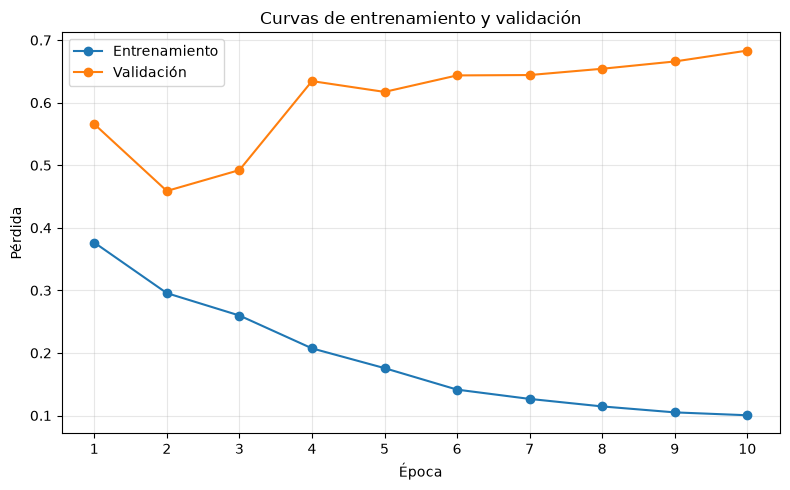

In [8]:
# -------------------------
# Gráfica
# -------------------------
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Entrenamiento")
plt.plot(epochs, val_losses, marker="o", label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Curvas de entrenamiento y validación")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Ejecución de FasterCNN
La ejecución se hace por medio de streaming tal cual si se tratase de la aplicación en tiempo real.  Se toma desde el código refactorizado en *"../Scripts/test_video.py"*.  
Se consideran adaptaciones para que al cerrar la ventana de ejecución con la tecla Q de OpenCV se muestre la última imágen clasificada en la libreta de Jupyter para efectos de documentación.  
**La celda a continuación es lo más parecido al modelo en su ejecución de producto final**

..\Models\best_fit.pth
Modelo cargado en: cpu


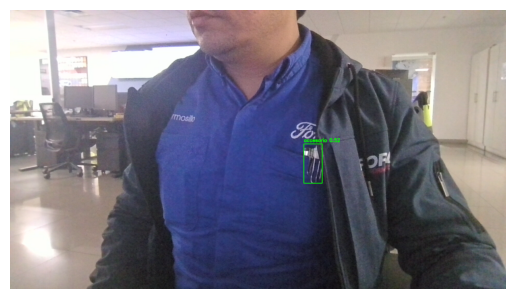

In [9]:
from pathlib import Path
import os
import matplotlib.pyplot as plt

model_path = Path("../Models/best_fit.pth")

import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

import cv2
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_file=model_path
print(checkpoint_file)

try:
    checkpoint = torch.load(
        checkpoint_file,
        map_location=device,
        weights_only=True
    )
except TypeError:
    # Compatibilidad con versiones anteriores de PyTorch.
    checkpoint = torch.load(checkpoint_file, map_location=device)

# Acepta el checkpoint con metadatos o un state_dict guardado directamente.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Reconstruye la misma arquitectura: Faster R-CNN, accesorio + fondo.
model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)

model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("Modelo cargado en:", device)


CAMERA_INDEX = 0          # Prueba 1 si la cámara principal no es la correcta.
SCORE_THRESHOLD = 0.50    # Usa el umbral que seleccionaste en validación.
MAX_AREA_FRACTION = 0.35  # Usa tu filtro elegido; pon None para desactivarlo.

cap = cv2.VideoCapture(CAMERA_INDEX)
# Configurar resolución deseada
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1920)  # Ancho
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 1080) # Alto

if not cap.isOpened():
    raise RuntimeError(
        "No se pudo abrir la webcam. Revisa CAMERA_INDEX y los permisos de cámara."
    )

frame_number = 0

try:
    while True:
        ok, frame_bgr = cap.read()
        if not ok:
            print("No se pudo leer un fotograma de la webcam.")
            break

        frame_number += 1
        height, width = frame_bgr.shape[:2]

        # OpenCV entrega BGR; el modelo recibe un tensor RGB con valores [0, 1].
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_tensor = (
            torch.from_numpy(frame_rgb)
            .permute(2, 0, 1)
            .float()
            .div(255.0)
            .to(device)
        )

        with torch.no_grad():
            prediction = model([image_tensor])[0]

        boxes = prediction["boxes"].detach().cpu().numpy()
        scores = prediction["scores"].detach().cpu().numpy()
        labels = prediction["labels"].detach().cpu().numpy()

        # Se llena con las detecciones conservadas de este fotograma,
        # en formato [x, y, w, h].
        detections_frame = []

        for box, score, label in zip(boxes, scores, labels):
            if score < SCORE_THRESHOLD or label != 1:
                continue

            x1, y1, x2, y2 = box
            x1 = int(np.clip(round(x1), 0, width - 1))
            y1 = int(np.clip(round(y1), 0, height - 1))
            x2 = int(np.clip(round(x2), 0, width - 1))
            y2 = int(np.clip(round(y2), 0, height - 1))

            box_width = x2 - x1
            box_height = y2 - y1
            if box_width <= 0 or box_height <= 0:
                continue

            area_fraction = (box_width * box_height) / (width * height)

            # Filtro opcional para omitir cajas demasiado grandes.
            if (
                MAX_AREA_FRACTION is not None
                and area_fraction > MAX_AREA_FRACTION
            ):
                continue

            detections_frame.append({
                "x": x1,
                "y": y1,
                "w": box_width,
                "h": box_height,
                "confianza": float(score),
            })

            cv2.rectangle(
                frame_bgr,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            texto = f"accesorio {score:.2f}"
            cv2.putText(
                frame_bgr,
                texto,
                (x1, max(22, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

            last_detection_frame = frame_bgr.copy()

        cv2.putText(
            frame_bgr,
            "Presiona q para salir",
            (10, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 255, 255),
            2
        )

        cv2.imshow("Detector en webcam", frame_bgr)

        # detections_frame contiene las cajas [x, y, w, h]
        # del fotograma actual, por si quieres inspeccionarlas:
        # print(frame_number, detections_frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord("q") or key == 27:
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
    plt.imshow(cv2.cvtColor(last_detection_frame, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

## Desempeño  
Para evaluar el desempeño es necesario medir los 4 modos de lectura:
* Verdaderos positivos
* Falsos positivos
* Verdaderos negativos
* Falsos negativos
  
Para ello se somete a prueba las predicciones sobre el dataset de validación.

In [10]:
import csv
from pathlib import Path

import torch

def exportar_predicciones_validacion(
    model,
    val_loader,
    device,
    csv_out,
    score_threshold=0.50,
    class_id=1,
):
    """
    Ejecuta inferencia sobre val_loader y guarda las predicciones en un CSV.

    El CSV usa las columnas:
    imagen, x, y, w, h, ImageWidth, ImageHeight
    """

    csv_out = Path(csv_out)
    csv_out.parent.mkdir(parents=True, exist_ok=True)

    columns = [
        "imagen", "x", "y", "w", "h", "ImageWidth", "ImageHeight"
    ]

    model.to(device)
    model.eval()

    total_images = 0
    total_boxes = 0

    with csv_out.open("w", newline="", encoding="utf-8-sig") as archivo:
        writer = csv.DictWriter(archivo, fieldnames=columns)
        writer.writeheader()

        with torch.inference_mode():
            for images, targets in val_loader:
                                
                images = [image.to(device) for image in images]
                predictions = model([image.to(device) for image in images])
                
                for image, target, prediction in zip(
                    images, targets, predictions
                ):
                    image_name = target.get("image_name")
                    if not image_name:
                        raise KeyError(
                            "No se encontró target['image_name']. "
                            "Añade el nombre del archivo al target en "
                            "__getitem__ del dataset."
                        )

                    # Las dimensiones corresponden al tensor entregado al modelo.
                    image_height, image_width = image.shape[-2:]

                    boxes = prediction["boxes"].detach().cpu()
                    scores = prediction["scores"].detach().cpu()
                    labels = prediction["labels"].detach().cpu()

                    rows_for_image = []

                    for box, score, label in zip(boxes, scores, labels):
                        if score.item() < score_threshold:
                            continue

                        # Esta salida replica una anotación de una sola clase.
                        # Cambia o elimina este filtro si tu modelo tiene varias clases.
                        if class_id is not None and label.item() != class_id:
                            continue

                        x1, y1, x2, y2 = box.tolist()

                        # Redondear y limitar las coordenadas a la imagen.
                        x1 = max(0, min(round(x1), image_width - 1))
                        y1 = max(0, min(round(y1), image_height - 1))
                        x2 = max(0, min(round(x2), image_width - 1))
                        y2 = max(0, min(round(y2), image_height - 1))

                        if x2 < x1 or y2 < y1:
                            continue

                        # +1 para seguir la convención del anotador manual,
                        # que cuenta ambos extremos de la caja.
                        width = x2 - x1 + 1
                        height = y2 - y1 + 1

                        rows_for_image.append({
                            "imagen": image_name,
                            "x": x1,
                            "y": y1,
                            "w": width,
                            "h": height,
                            "ImageWidth": image_width,
                            "ImageHeight": image_height,
                        })

                    if rows_for_image:
                        writer.writerows(rows_for_image)
                        total_boxes += len(rows_for_image)
                    else:
                        # Mantiene una fila por imagen incluso si el modelo
                        # no encuentra detecciones sobre el umbral.
                        writer.writerow({
                            "imagen": image_name,
                            "x": "",
                            "y": "",
                            "w": "",
                            "h": "",
                            "ImageWidth": image_width,
                            "ImageHeight": image_height,
                        })

                    total_images += 1

    print(f"Imágenes procesadas: {total_images}")
    print(f"Cajas predichas: {total_boxes}")
    print(f"CSV de predicciones guardado: {csv_out}")


In [11]:
actual_dir = Path("..").resolve()
CSV_FASTER_VAL = actual_dir / "DataCapture/Anotaciones_FasterrVal.csv"

exportar_predicciones_validacion(
    model=model,
    val_loader=val_loader,
    device=device,
    csv_out=CSV_FASTER_VAL,
    score_threshold=0.50,
    class_id=1,
)


Imágenes procesadas: 8
Cajas predichas: 8
CSV de predicciones guardado: C:\Users\mlope243\Documents\VSCode\TC5031.10_ProyectoIntegrador\DataCapture\Anotaciones_FasterrVal.csv


In [12]:
import pandas as pd
val_predictions = pd.read_csv(CSV_FASTER_VAL)
val_images=val_predictions["imagen"].unique()
val_predictions

,imagen,x,y,w,h,ImageWidth,ImageHeight
0,captura_20261003_153101_657504.jpg,244.0,215.0,16.0,16.0,640,480
1,captura_20261003_154700_253089.jpg,NaN,NaN,NaN,NaN,640,480
2,captura_20261003_162111_400265.jpg,0.0,0.0,640.0,480.0,640,480
3,captura_20261003_162116_408782.jpg,0.0,0.0,640.0,480.0,640,480
4,captura_20261003_221702_750284.jpg,327.0,171.0,26.0,21.0,640,480
5,captura_20261003_221717_781755.jpg,318.0,224.0,20.0,21.0,640,480
6,captura_20261003_221717_781755.jpg,140.0,98.0,27.0,95.0,640,480
7,captura_20261019_105151_407042.jpg,NaN,NaN,NaN,NaN,1920,1080
8,captura_20261101_155245_907575.jpg,808.0,603.0,46.0,47.0,1920,1080
9,captura_20261101_155245_907575.jpg,838.0,858.0,49.0,38.0,1920,1080


In [13]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Patch, Rectangle


def mostrar_muestras_validacion(
    model,
    val_dataset,
    device,
    num_imagenes=8,
    score_threshold=0.50,
    class_id=1,
    seed=42,
    ncols=4,
):
    """
    Muestra una selección aleatoria del dataset de validación.

    Cajas reales: verde.
    Cajas predichas: rojo.
    """

    if len(val_dataset) == 0:
        print("El dataset de validación está vacío.")
        return

    cantidad = min(num_imagenes, len(val_dataset))
    indices = random.Random(seed).sample(range(len(val_dataset)), cantidad)

    muestras = [val_dataset[i] for i in indices]
    images = [muestra[0] for muestra in muestras]
    targets = [muestra[1] for muestra in muestras]

    # Conserva el modo previo del modelo y lo restaura al terminar.
    estaba_entrenando = model.training
    model.eval()

    try:
        with torch.inference_mode():
            predictions = model([image.to(device) for image in images])
    finally:
        model.train(estaba_entrenando)

    # Guarda las imágenes, cajas reales y predicciones listas para graficar.
    resultados = []

    for indice, image, target, prediction in zip(
        indices, images, targets, predictions
    ):
        image_np = image.detach().cpu().permute(1, 2, 0).numpy()
        image_np = np.clip(image_np, 0, 1)

        gt_boxes = target["boxes"].detach().cpu().numpy()

        pred_boxes = prediction["boxes"].detach().cpu().numpy()
        pred_scores = prediction["scores"].detach().cpu().numpy()
        pred_labels = prediction["labels"].detach().cpu().numpy()

        conservar = pred_scores >= score_threshold
        if class_id is not None:
            conservar &= pred_labels == class_id

        pred_boxes = pred_boxes[conservar]
        pred_scores = pred_scores[conservar]

        image_name = target.get("image_name", f"Índice {indice}")

        resultados.append(
            (image_np, gt_boxes, pred_boxes, pred_scores, image_name)
        )

    nrows = (cantidad + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 4.5 * nrows),
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, resultado in zip(axes, resultados):
        image_np, gt_boxes, pred_boxes, pred_scores, image_name = resultado
        alto, ancho = image_np.shape[:2]

        ax.imshow(image_np)

        # Anotaciones reales.
        for x1, y1, x2, y2 in gt_boxes:
            ax.add_patch(
                Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    fill=False,
                    edgecolor="lime",
                    linewidth=2,
                )
            )

        # Predicciones que superan el umbral de confianza.
        for (x1, y1, x2, y2), score in zip(pred_boxes, pred_scores):
            ax.add_patch(
                Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    fill=False,
                    edgecolor="red",
                    linewidth=2,
                )
            )
            ax.text(
                x1,
                max(y1 - 4, 0),
                f"{score:.2f}",
                color="white",
                fontsize=8,
                bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
            )

        ax.set_title(
            f"{image_name}\n"
            f"Reales: {len(gt_boxes)} | Predichas: {len(pred_boxes)}",
            fontsize=9,
        )
        ax.set_xlim(0, ancho)
        ax.set_ylim(alto, 0)
        ax.axis("off")

    # Oculta los paneles sobrantes si la cantidad no llena la cuadrícula.
    for ax in axes[len(resultados):]:
        ax.axis("off")

    leyenda = [
        Patch(facecolor="none", edgecolor="lime", linewidth=2,
              label="Caja real"),
        Patch(facecolor="none", edgecolor="red", linewidth=2,
              label="Caja predicha"),
    ]

    fig.legend(handles=leyenda, loc="upper center", ncol=2)
    fig.suptitle(
        f"Muestras aleatorias de validación "
        f"(umbral de puntuación: {score_threshold:.2f})",
        y=0.99,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


### Prueba de detecciones con set de validación

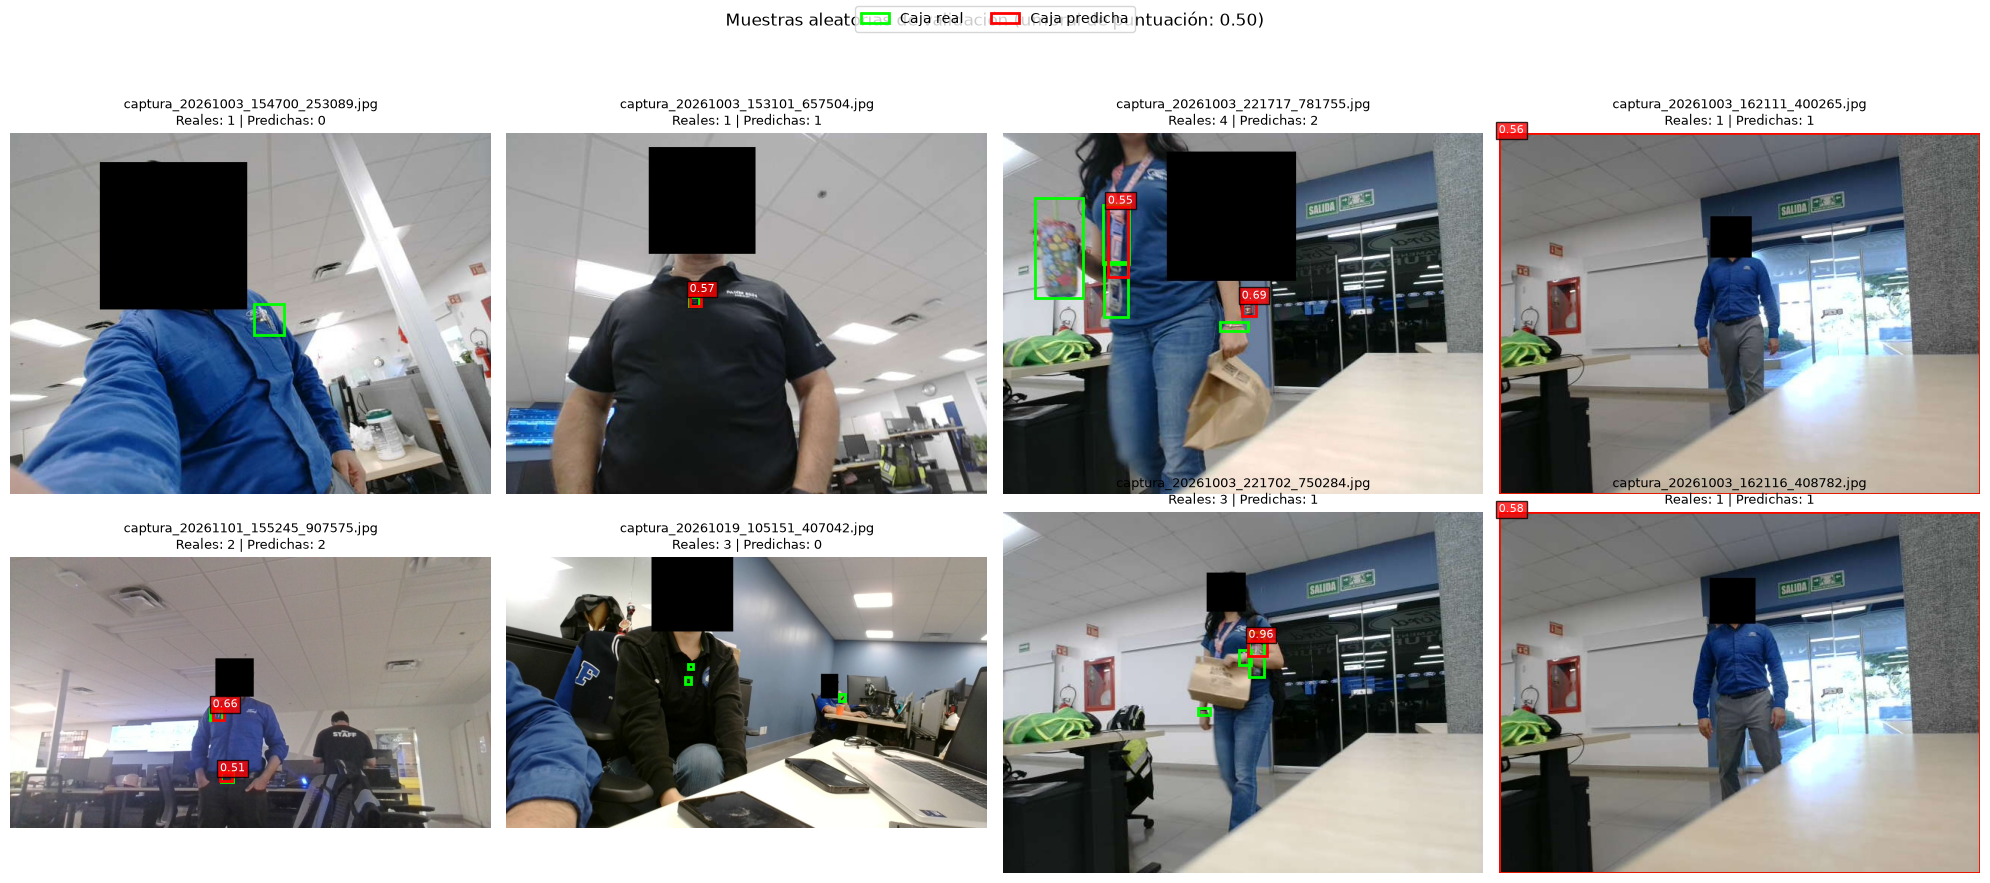

In [14]:
mostrar_muestras_validacion(
    model=model,
    val_dataset=val_dataset,
    device=device,
    num_imagenes=8,
    score_threshold=0.50,
    class_id=1,
    seed=42,
)


### Aumentando la sensibilidad

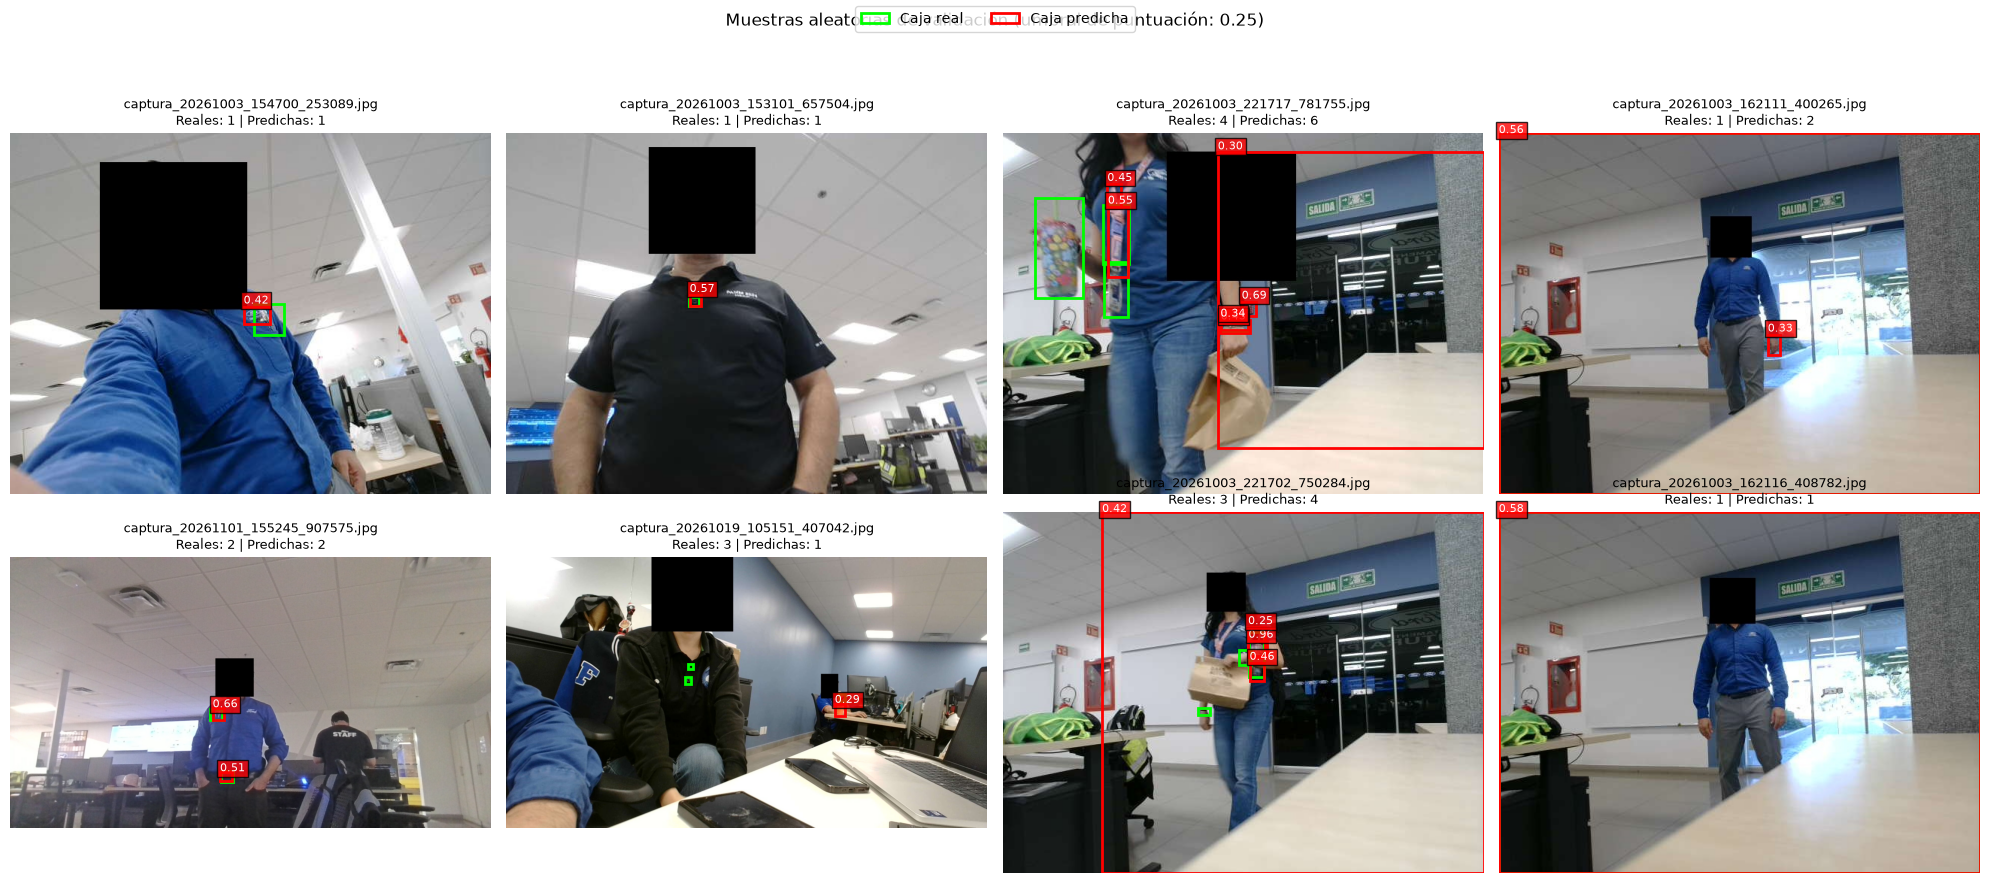

In [16]:
mostrar_muestras_validacion(
    model=model,
    val_dataset=val_dataset,
    device=device,
    num_imagenes=8,
    score_threshold=0.25,
    class_id=1,
    seed=42,
)

## Métricas de desempeño  
De las cajas que el modelo arroja y las cajas que existen en el set de entrenamiento es posible calcular las métricas de la siguiente forma:  
* **Verdaderos positivos**. Cajas superpuestas con tamaños similares
* **Falsos positivos**.  Cajas del modelo que no se trasponen a cajas del entrenamiento
* **Verdaderos negativos**.  Ausencia de caja en imagenes "sin objetos".
* **Falsos negativos**.  Cajas del entrenamiento que el modelo no encontró.

A partir de ahí se puede construir la matriz de confusión